# 08 — Evaluación de relevancia temática (NLI)

## Objetivo

Evaluar el rendimiento de tres estrategias de clasificación
de relevancia temática aplicadas a noticias sobre inteligencia
artificial:

1. Recuperación mediante palabras clave.
2. Clasificación semántica mediante NLI.
3. Estrategia combinada (palabras clave + recuperación NLI).

La evaluación utiliza un corpus de 186 noticias y un conjunto
de referencia binario obtenido mediante revisión asistida por
inteligencia artificial y confirmación humana.

Se calculan matrices de confusión, Precision, Recall,
F1-score y Accuracy para comparar el comportamiento de
las estrategias.

El procedimiento recupera las predicciones almacenadas
en PostgreSQL sin modificar los modelos, sus parámetros
ni los registros de la base de datos.

**Alcance:** los resultados describen el comportamiento
sobre el corpus estudiado, previamente utilizado durante
la experimentación, y no constituyen una estimación
independiente de generalización.

## 1. Cargar las noticias originales

Se espera el mismo corpus de 186 noticias utilizado en los notebooks anteriores. Si la base cambió, se detiene el procedimiento para evitar una comparación inválida.

## 2. Construcción del conjunto de referencia

Se establecieron etiquetas binarias para las 186 noticias
del corpus mediante un proceso de revisión asistida por
inteligencia artificial y confirmación humana.

Se adoptaron los siguientes criterios:

- **1 — Relevante:** la inteligencia artificial constituye
  un tema sustancial de la noticia, incluyendo desarrollos,
  aplicaciones, infraestructura, riesgos, impactos o
  regulación.
- **0 — No relevante:** la inteligencia artificial aparece
  de manera incidental o la noticia trata principalmente
  sobre otros temas tecnológicos, científicos o generales.

La revisión contempló el título, la descripción y el
contenido disponible de cada noticia. En algunos registros,
el contenido disponible fue limitado.

Las etiquetas se incorporan mediante un conjunto explícito
de identificadores en Python, sin persistir cambios
en PostgreSQL.

### Distribución de referencia

- Total: 186 noticias.
- Relevantes: 38 (20,43 %).
- No relevantes: 148 (79,57 %).

El conjunto constituye una referencia revisada, pero no
una anotación independiente realizada por múltiples
evaluadores.

In [35]:
from pathlib import Path
import sys

import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.database.connection import get_connection

# Recuperar el corpus completo desde PostgreSQL.
query = """
    SELECT rss_news_id, title, description
    FROM rss_news
    ORDER BY rss_news_id;
"""

with get_connection() as connection:
    with connection.cursor() as cursor:
        cursor.execute(query)
        columns = [column.name for column in cursor.description]
        news = pd.DataFrame(cursor.fetchall(), columns=columns)

# Verificar que el corpus corresponde al revisado.
expected_ids = set(range(1, 187))

assert len(news) == 186
assert news["rss_news_id"].is_unique
assert set(news["rss_news_id"]) == expected_ids

# Etiquetas definitivas de la revisión humana asistida.
# 1 = relevante para inteligencia artificial
# 0 = no relevante

relevant_ids = {
    3, 7, 8,
    13, 16, 17, 21, 26, 27, 30, 32, 35, 39,
    48, 49, 52, 66,
    71, 80, 82, 85, 89, 93, 96,
    109, 114, 116, 117, 119, 122, 125, 135, 136,
    148, 149, 150, 154, 166
}

assert len(relevant_ids) == 38
assert relevant_ids <= expected_ids

# Todos los IDs no incluidos se consideran no relevantes.
news["reference_label"] = (
    news["rss_news_id"].isin(relevant_ids).astype(int)
)

print(f"Noticias del corpus: {len(news)}")
print("\nDistribución de etiquetas:")
print(news["reference_label"].value_counts().sort_index())

display(news.head())

Noticias del corpus: 186

Distribución de etiquetas:
reference_label
0    148
1     38
Name: count, dtype: int64


,rss_news_id,title,description,reference_label
0,1,Guía para obtener 15 GB de espacio gratis en G...,"Videos, respaldos antiguos e instaladores suel...",0
1,2,Epic Games Store regala un nuevo juego de terr...,La tienda suma un indie de supervivencia y exp...,0
2,3,Bill Gates advierte sobre la IA: “será el mayo...,"Según el fundador de Microsoft, esta tecnologí...",1
3,4,WhatsApp refuerza la seguridad de las cuentas ...,La nueva función busca combatir las tácticas d...,0
4,5,Gratis en Steam: el juego que combina superviv...,El juego mezcla supervivencia con dinosaurios ...,0


In [36]:
# Mostrar descripciones completas en Pandas.
pd.set_option("display.max_colwidth", None)

# Comprobar longitud y contenido de una descripción.
example = news.loc[news["rss_news_id"] == 21].iloc[0]

print(f"ID: {example['rss_news_id']}")
print(f"Título: {example['title']}")
print(f"Longitud descripción: {len(example['description'] or '')} caracteres")
print(f"\nDescripción completa:\n{example['description']}")

ID: 21
Título: Amazon se une a Nvidia y tendrá dos millones de chips para sus centros de datos
Longitud descripción: 135 caracteres

Descripción completa:
El gigante tecnológico desplegará los nuevos procesadores de Nvidia entre 2027 y 2028 para ampliar la capacidad de sus centros de datos


## 3. Recuperación de las predicciones del pipeline

Se recuperan desde PostgreSQL las predicciones generadas
por el notebook `04_Clasificacion_semantica_relevancia.ipynb`.

Se comparan tres estrategias:

- **Palabras clave:** selección mediante coincidencias léxicas.
- **NLI:** clasificación según la probabilidad de entailment
  respecto de la hipótesis "La noticia habla sobre
  inteligencia artificial.", con umbral 0,5.
- **Combinado:** unión de noticias identificadas mediante
  palabras clave y noticias adicionales recuperadas por NLI.

El modelo utilizado es
`MoritzLaurer/mDeBERTa-v3-base-mnli-xnli`.

Las entradas originales del NLI combinan el título y la
descripción de cada noticia. La tokenización utiliza un
máximo de 512 tokens, con truncamiento del texto de la
noticia si supera ese límite.

Las 186 noticias poseen etiquetas binarias definitivas,
por lo que no se excluyen registros de la evaluación.

Las predicciones se recuperan sin volver a ejecutar
el modelo.

In [39]:
# Recuperar las predicciones de relevancia almacenadas.
query = """
    SELECT
        rss_news_id,
        topic,
        hypothesis,
        model_name,
        nli_score,
        keyword_match,
        nli_recovered,
        recovery_threshold
    FROM nli_news
    WHERE topic = %s
    ORDER BY rss_news_id;
"""

with get_connection() as connection:
    with connection.cursor() as cursor:
        cursor.execute(query, ("inteligencia_artificial",))
        columns = [column.name for column in cursor.description]
        nli_predictions = pd.DataFrame(
            cursor.fetchall(),
            columns=columns,
        )

# Verificar que se recuperaron las 186 noticias.
assert len(nli_predictions) == 186
assert nli_predictions["rss_news_id"].is_unique

# Unir las predicciones con las etiquetas definitivas.
evaluation_data = news.merge(
    nli_predictions,
    on="rss_news_id",
    how="inner",
    validate="one_to_one",
)

assert len(evaluation_data) == 186
assert evaluation_data["reference_label"].notna().all()
assert evaluation_data["reference_label"].isin([0, 1]).all()

# Reconstruir las tres estrategias de clasificación.
evaluation_data["pred_keywords"] = (
    evaluation_data["keyword_match"].astype(int)
)

evaluation_data["pred_nli"] = (
    evaluation_data["nli_score"].astype(float) >= 0.5
).astype(int)

evaluation_data["pred_combined"] = (
    evaluation_data["keyword_match"].astype(bool)
    | evaluation_data["nli_recovered"].astype(bool)
).astype(int)

# Mostrar resultados.
print("Noticias evaluables:", len(evaluation_data))

print("\nDistribución de etiquetas definitivas:")
print(
    evaluation_data["reference_label"]
    .value_counts()
    .sort_index()
)

print("\nNoticias seleccionadas por estrategia:")
print(
    evaluation_data[
        ["pred_keywords", "pred_nli", "pred_combined"]
    ].sum()
)

Noticias evaluables: 186

Distribución de etiquetas definitivas:
reference_label
0    148
1     38
Name: count, dtype: int64

Noticias seleccionadas por estrategia:
pred_keywords    72
pred_nli         30
pred_combined    76
dtype: int64


In [46]:
# Verificar configuración de inferencia y consistencia del corpus.

assert evaluation_data["rss_news_id"].is_unique
assert len(evaluation_data) == 186

assert evaluation_data["hypothesis"].eq(
    "La noticia habla sobre inteligencia artificial."
).all()

assert evaluation_data["model_name"].eq(
    "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
).all()

assert evaluation_data["recovery_threshold"].astype(float).eq(0.5).all()

assert evaluation_data["nli_score"].notna().all()
assert evaluation_data["nli_score"].astype(float).between(0, 1).all()

assert evaluation_data[
    ["pred_keywords", "pred_nli", "pred_combined"]
].isin([0, 1]).all().all()

# Confirmar que la estrategia combinada no elimina
# noticias seleccionadas por palabras clave.
assert (
    evaluation_data["pred_combined"]
    >= evaluation_data["pred_keywords"]
).all()

print("Validaciones metodológicas superadas.")

Validaciones metodológicas superadas.


## Evaluación comparativa de relevancia temática

Se comparan las predicciones de las tres estrategias
contra las etiquetas de referencia revisadas para
las 186 noticias.

Se calculan:

- Verdaderos positivos (TP).
- Falsos positivos (FP).
- Falsos negativos (FN).
- Verdaderos negativos (TN).
- Precision, Recall y F1-score para la clase relevante (1).
- Accuracy global.

Dado que las clases están desbalanceadas, el análisis
prioriza Precision, Recall y F1-score, utilizando Accuracy
como medida complementaria.

Las métricas permiten cuantificar tanto la capacidad de
recuperar noticias relevantes como la incorporación de
noticias que no corresponden a la temática.

La evaluación es descriptiva del corpus estudiado y
no representa una prueba independiente sobre noticias
no observadas durante la experimentación.

In [40]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# Estrategias de clasificación.
strategies = {
    "Palabras clave": "pred_keywords",
    "NLI": "pred_nli",
    "Combinado": "pred_combined",
}

# Etiquetas definitivas de referencia.
y_true = evaluation_data["reference_label"].astype(int)

metrics_rows = []

for strategy_name, prediction_column in strategies.items():
    y_pred = evaluation_data[prediction_column].astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    metrics_rows.append({
        "Estrategia": strategy_name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Accuracy": accuracy_score(y_true, y_pred),
    })

metrics_df = pd.DataFrame(metrics_rows)

display(metrics_df.round(4))

,Estrategia,TP,FP,FN,TN,Precision,Recall,F1,Accuracy
0,Palabras clave,38,34,0,114,0.5278,1.0000,0.6909,0.8172
1,NLI,22,8,16,140,0.7333,0.5789,0.6471,0.8710
2,Combinado,38,38,0,110,0.5000,1.0000,0.6667,0.7957


## 7. Análisis de falsos positivos y falsos negativos

Se examinan las discrepancias entre las etiquetas de referencia y las predicciones de las tres estrategias.

Los falsos positivos corresponden a noticias seleccionadas como relevantes que fueron etiquetadas como no relevantes. Los falsos negativos corresponden a noticias relevantes que no fueron seleccionadas.

El análisis permite identificar patrones de error y comprender las ventajas y limitaciones de cada estrategia.

In [41]:
# Analizar falsos positivos y falsos negativos por estrategia.

for strategy_name, prediction_column in strategies.items():
    print(f"\n{'=' * 60}")
    print(f"Estrategia: {strategy_name}")

    false_positives = evaluation_data[
        (evaluation_data["reference_label"] == 0)
        & (evaluation_data[prediction_column] == 1)
    ]

    false_negatives = evaluation_data[
        (evaluation_data["reference_label"] == 1)
        & (evaluation_data[prediction_column] == 0)
    ]

    print(f"Falsos positivos: {len(false_positives)}")
    print(f"Falsos negativos: {len(false_negatives)}")

    print("\nEjemplos de falsos positivos:")
    display(
        false_positives[
            ["rss_news_id", "title", "nli_score"]
        ].head(5)
    )

    print("\nEjemplos de falsos negativos:")
    display(
        false_negatives[
            ["rss_news_id", "title", "nli_score"]
        ].head(5)
    )


Estrategia: Palabras clave
Falsos positivos: 34
Falsos negativos: 0

Ejemplos de falsos positivos:


,rss_news_id,title,nli_score
11,12,El costo de Bitcoin para este jueves,0.000291
18,19,Propinas para robots: la polémica detrás de la automatización en bares y cafeterías,0.989592
23,24,Un robot humanoide supera el récord humano de salto en alto: casi alcanza los tres metros,0.347396
35,36,La puerta es el mejor lugar para guardar los lácteos: un mito muy común de los refrigeradores,0.000140
41,42,América Latina en el centro de la estrategia tecnológica de la industria aumotriz: electrificación y seguridad,0.001128



Ejemplos de falsos negativos:


,rss_news_id,title,nli_score



Estrategia: NLI
Falsos positivos: 8
Falsos negativos: 16

Ejemplos de falsos positivos:


,rss_news_id,title,nli_score
18,19,Propinas para robots: la polémica detrás de la automatización en bares y cafeterías,0.989592
22,23,Por qué Londres está frenando la llegada de los robotaxis a pesar de que Uber ya tiene la licencia,0.991196
45,46,Gleeden anuncia podcast sobre infidelidad y no monogamia: el desafio tecnológico de las relaciones,0.975158
86,87,Waymo lleva sus robotaxis a Múnich y prepara su desembarco en Alemania,0.995326
94,95,Demis Hassabis IQ: este sería el coeficiente intelectual del científico detrás de la estrategia de IA de Google,0.967277


... (2 outputs left out)


Estrategia: Combinado
Falsos positivos: 38
Falsos negativos: 0

Ejemplos de falsos positivos:


,rss_news_id,title,nli_score
11,12,El costo de Bitcoin para este jueves,0.000291
18,19,Propinas para robots: la polémica detrás de la automatización en bares y cafeterías,0.989592
22,23,Por qué Londres está frenando la llegada de los robotaxis a pesar de que Uber ya tiene la licencia,0.991196
23,24,Un robot humanoide supera el récord humano de salto en alto: casi alcanza los tres metros,0.347396
35,36,La puerta es el mejor lugar para guardar los lácteos: un mito muy común de los refrigeradores,0.000140



Ejemplos de falsos negativos:


,rss_news_id,title,nli_score


-----

In [44]:
import matplotlib.pyplot as plt
import pandas as pd

# Tabla comparativa en porcentajes.
comparison_table = metrics_df[
    ["Estrategia", "Precision", "Recall", "F1", "Accuracy"]
].copy()

for column in ["Precision", "Recall", "F1", "Accuracy"]:
    comparison_table[column] = comparison_table[column] * 100

comparison_table = comparison_table.rename(
    columns={
        "Precision": "Precisión (%)",
        "Recall": "Recall (%)",
        "F1": "F1-score (%)",
        "Accuracy": "Exactitud (%)",
    }
)

display(comparison_table.round(2))

# Exportar para el informe.
comparison_table.round(2).to_csv(
    "comparacion_estrategias.csv",
    index=False,
    encoding="utf-8-sig",
)

,Estrategia,Precisión (%),Recall (%),F1-score (%),Exactitud (%)
0,Palabras clave,52.78,100.00,69.09,81.72
1,NLI,73.33,57.89,64.71,87.10
2,Combinado,50.00,100.00,66.67,79.57


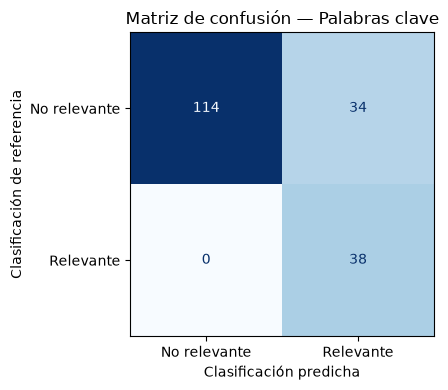

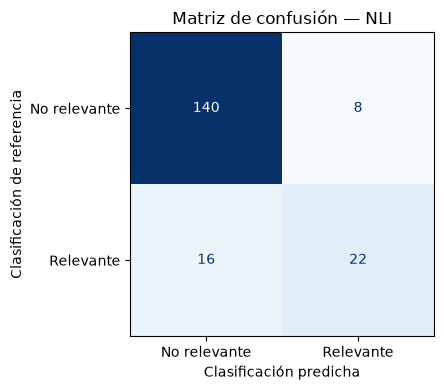

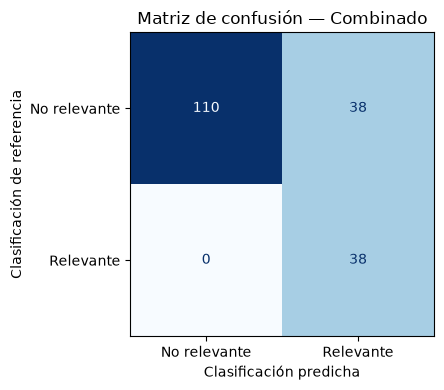

In [45]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

y_true = evaluation_data["reference_label"].astype(int)

for strategy_name, prediction_column in strategies.items():
    y_pred = evaluation_data[prediction_column].astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    fig, ax = plt.subplots(figsize=(5, 4))

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No relevante", "Relevante"],
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False,
    )

    ax.set_title(f"Matriz de confusión — {strategy_name}")
    ax.set_xlabel("Clasificación predicha")
    ax.set_ylabel("Clasificación de referencia")

    plt.tight_layout()

    filename = (
        strategy_name.lower()
        .replace(" ", "_")
    )

    fig.savefig(
        f"matriz_confusion_{filename}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

## Conclusiones de la evaluación

### Resultados principales

La evaluación de 186 noticias permitió comparar tres
estrategias de identificación de información relevante
sobre inteligencia artificial.

La estrategia de palabras clave obtuvo el mayor F1-score
(0,6909) y un Recall de 1,0000, recuperando las 38 noticias
relevantes. Sin embargo, produjo 34 falsos positivos,
lo que evidencia una capacidad limitada para descartar
noticias ajenas a la temática.

La estrategia NLI alcanzó la mayor Precision (0,7333)
y Accuracy (0,8710), con solamente 8 falsos positivos.
No obstante, omitió 16 noticias relevantes y obtuvo un
Recall de 0,5789. Entre los casos omitidos se encuentran
noticias sobre infraestructura, productos y aplicaciones
de inteligencia artificial.

La estrategia combinada conservó un Recall de 1,0000,
pero produjo 38 falsos positivos y obtuvo un F1-score
de 0,6667. La combinación mediante una operación OR
incorporó cuatro noticias no relevantes adicionales
respecto de las palabras clave, sin recuperar nuevos
verdaderos positivos.

### Interpretación

Los resultados evidencian un compromiso entre
cobertura y precisión:

- Las palabras clave favorecen la recuperación exhaustiva.
- NLI ofrece mayor precisión, pero menor cobertura.
- La combinación OR no mejoró el F1-score frente
  a la estrategia de palabras clave.

Para el corpus evaluado, las palabras clave obtuvieron
el mejor equilibrio según F1-score, mientras que NLI
demostró mayor capacidad de selección precisa.

### Limitaciones metodológicas

La evaluación presenta las siguientes limitaciones:

1. El corpus fue utilizado previamente durante la
   experimentación y no constituye un conjunto
   independiente de prueba.

2. Las etiquetas de referencia fueron obtenidas mediante
   revisión asistida por IA y confirmación humana, sin
   anotadores independientes ni medición de acuerdo.

3. Algunos registros disponían únicamente de descripciones
   o fragmentos de contenido, lo que limita la evaluación
   del tema principal de ciertas noticias.

4. El corpus puede contener noticias duplicadas o
   temáticamente similares, que no fueron excluidas
   de esta evaluación.

5. El modelo NLI utiliza el título y la descripción,
   sujetos al límite de 512 tokens de su entrada.

6. Los resultados corresponden a una única temática,
   un modelo NLI y una configuración de umbral específica.

### Trabajo futuro

Como posibles mejoras se plantea evaluar nuevas estrategias
de combinación de clasificadores, revisar hipótesis y
umbrales mediante conjuntos de validación separados y
comprobar el rendimiento sobre noticias nuevas.

También podría incorporarse un proceso de anotación
independiente para fortalecer la confiabilidad
de las etiquetas de referencia.

### Conclusión general

La evaluación permitió caracterizar las ventajas y
limitaciones de las estrategias de relevancia temática
implementadas en el prototipo.

Los resultados proporcionan evidencia empírica para
justificar futuras decisiones de diseño del sistema,
sin asumir que el rendimiento observado se mantendrá
necesariamente en otros conjuntos de noticias.